In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("data (1).csv" , encoding = "latin1")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [4]:
df.shape

(541909, 8)

In [5]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.3 MB


In [7]:
# check the missing values
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [8]:
# check duplicates
df.duplicated().sum()

np.int64(5268)

In [9]:
df=df.dropna(subset = "CustomerID")

In [10]:
df.isnull().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(5225)

In [12]:
df=df.drop_duplicates()

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df.shape

(401604, 8)

In [15]:

'''
STEP 5 - Handle Cancelled orders
Important

Agar InvoiceNo me C hai --> order cancelled hai
'''

df = df[~df['InvoiceNo'].astype(str).str.contains("C")]
df.shape

(392732, 8)

In [16]:
df = df[df['Quantity']>0]

In [17]:
# convert data column
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [18]:
df.info()

<class 'pandas.DataFrame'>
Index: 392732 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    392732 non-null  str           
 1   StockCode    392732 non-null  str           
 2   Description  392732 non-null  str           
 3   Quantity     392732 non-null  int64         
 4   InvoiceDate  392732 non-null  datetime64[us]
 5   UnitPrice    392732 non-null  float64       
 6   CustomerID   392732 non-null  float64       
 7   Country      392732 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 46.2 MB


In [19]:
# step 8 -- > Create a Revenue Column important
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

In [20]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [21]:
# Step 9 ---> FEATURE ENGINEERING , create month column
df['Month'] = df['InvoiceDate'].dt.month

In [22]:
# create your own

df["Week"] = df['InvoiceDate'].dt.day_name()

In [23]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month,Week
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,12,Wednesday
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,Wednesday
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,12,Wednesday
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,Wednesday
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,Wednesday


In [24]:
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month,Week
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France,10.20,12,Friday
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France,12.60,12,Friday
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,12,Friday
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France,16.60,12,Friday
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France,14.85,12,Friday


In [25]:
# Step 10 ------> EXPLORATORY DATA ANALYSIS

# 1. TOTAL REVENUE
total_revenue = df["Revenue"].sum()

In [26]:
print(total_revenue)

8887208.894


In [27]:
# Top 10 Products 
top_products = df.groupby("Description")["Revenue"].sum().sort_values(ascending= False).head(10)

print(top_products)

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142264.75
WHITE HANGING HEART T-LIGHT HOLDER    100392.10
JUMBO BAG RED RETROSPOT                85040.54
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
POSTAGE                                77803.96
PARTY BUNTING                          68785.23
ASSORTED COLOUR BIRD ORNAMENT          56413.03
Manual                                 53419.93
RABBIT NIGHT LIGHT                     51251.24
Name: Revenue, dtype: float64


In [28]:
# TOP 10 COUNTRY
top_country = df.groupby("Country")["Revenue"].sum().sort_values(ascending= False).head(10)

print(top_country)

Country
United Kingdom    7285024.644
Netherlands        285446.340
EIRE               265262.460
Germany            228678.400
France             208934.310
Australia          138453.810
Spain               61558.560
Switzerland         56443.950
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64


In [29]:
# MONTHLY SALES

monthly_sales = df.groupby("Month")["Revenue"].sum()

monthly_sales

Month
1      568101.310
2      446084.920
3      594081.760
4      468374.331
5      677355.150
6      660046.050
7      598962.901
8      644051.040
9      950690.202
10    1035642.450
11    1156205.610
12    1087613.170
Name: Revenue, dtype: float64

In [30]:
# BEST SELLING DAY

best_day = df.groupby("Week")["Revenue"].sum().sort_values(ascending = False)

best_day

Week
Thursday     1973015.730
Tuesday      1697733.801
Wednesday    1584283.830
Friday       1483080.811
Monday       1363604.401
Sunday        785490.321
Name: Revenue, dtype: float64

In [31]:
best_day.max()

np.float64(1973015.73)

In [40]:
# repeated customers
repeated_customers = df["CustomerID"].value_counts()
print(repeated_customers)

CustomerID
17841.0    7676
14911.0    5672
14096.0    5111
12748.0    4413
14606.0    2677
           ... 
18184.0       1
13256.0       1
13017.0       1
18174.0       1
15195.0       1
Name: count, Length: 4339, dtype: int64


In [41]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'Revenue', 'Month', 'Week'],
      dtype='str')

In [45]:
# find those customer who have placed more 1000 order

repeated_customers_grtr_1000 = df["CustomerID"].value_counts()>=1000
print(repeated_customers_grtr_1000)

CustomerID
17841.0     True
14911.0     True
14096.0     True
12748.0     True
14606.0     True
           ...  
18184.0    False
13256.0    False
13017.0    False
18174.0    False
15195.0    False
Name: count, Length: 4339, dtype: bool


In [49]:
repeated_customers = df.groupby("CustomerID")["CustomerID"].count().sort_values(ascending = False).head(25)
print(repeated_customers)

CustomerID
17841.0    7676
14911.0    5672
14096.0    5111
12748.0    4413
14606.0    2677
15311.0    2366
14646.0    2080
13089.0    1814
13263.0    1667
14298.0    1637
15039.0    1477
14156.0    1395
18118.0    1263
14159.0    1175
14796.0    1132
16033.0    1128
15005.0    1112
14056.0    1088
14769.0    1062
13081.0    1028
14527.0     971
17511.0     963
14456.0     947
15719.0     931
16549.0     925
Name: CustomerID, dtype: int64


# DATA VISULIZATION

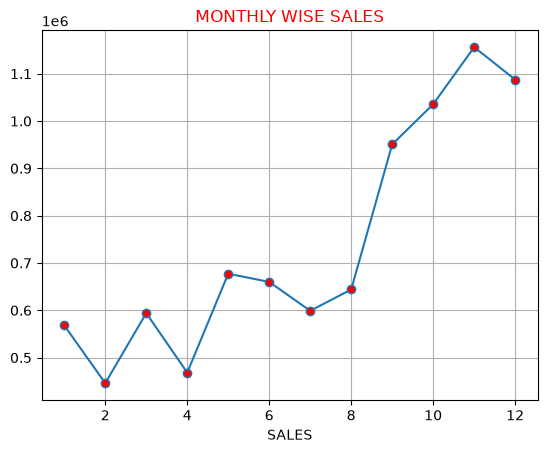

In [50]:
plt.plot(monthly_sales.index,monthly_sales.values,marker='o',markerfacecolor="red")
plt.grid()
plt.title("MONTHLY WISE SALES",color = "red")
plt.xlabel("MONTH")
plt.xlabel("SALES")
plt.show()

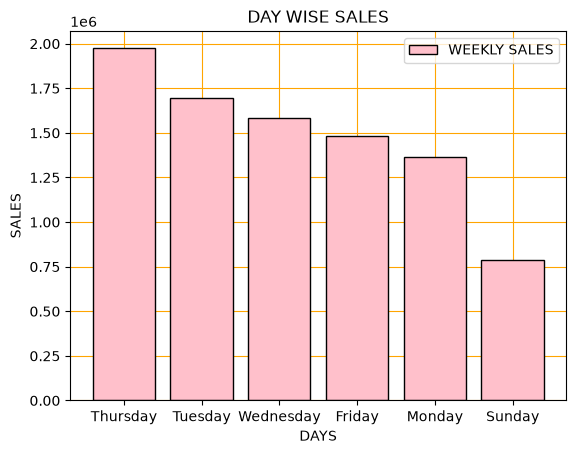

In [54]:
plt.bar(best_day.index,best_day.values,color = "pink",edgecolor = "black",label="WEEKLY SALES",zorder=2)
plt.title("DAY WISE SALES")
plt.xlabel("DAYS")
plt.ylabel("SALES")
plt.legend()
plt.grid(color="orange")
plt.show()

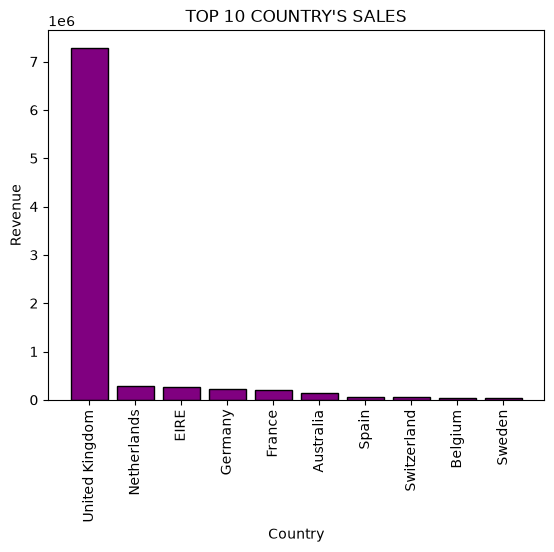

In [58]:
plt.bar(top_country.index,top_country.values,color = "purple",edgecolor = "black")
plt.xticks(rotation = 90)
plt.xlabel("Country")
plt.ylabel("Revenue")
plt.title("TOP 10 COUNTRY'S SALES")
plt.show()

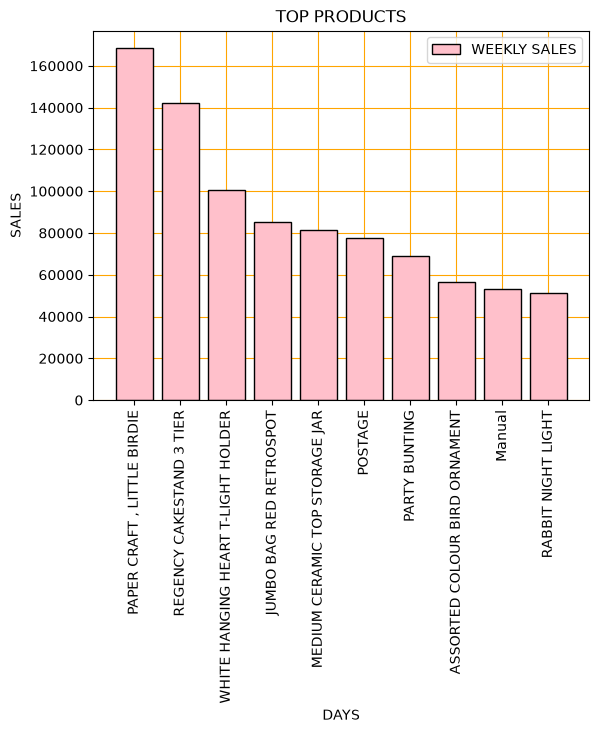

In [60]:
plt.bar(top_products.index,top_products.values,color = "pink",edgecolor = "black",label="WEEKLY SALES",zorder=2)
plt.xticks(rotation = 90)
plt.title("TOP PRODUCTS")
plt.xlabel("DAYS")
plt.ylabel("SALES")
plt.legend()
plt.grid(color="orange")
plt.show()

# BUSINESS INSIGTS

In [ ]:
# United Kingdom generated highest revenue. 
# November had highest sales. Few customers contributed major revenue. 
# Certain products dominate total sales. 
# Weekend sales are higher on thrusday.